# 구룡포시장 | 외곽형

* 자료: 공개 가능한 저장 요약값
* 관측 단위: 시장 소재 행정동, 실제 방문·구매 미확인
* 공개 범위: OD·STAY 원자료 제외

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from plotting import (FIGS, HOUR, WEEK, STAY, CASE_COMPARISONS, STAY_CASES, TIME_FIGURES,
                      plot_case_comparison, plot_stay_case, plot_time_weekday)
CASE = '구룡포시장'


## 이동·체류와 비교 기준

,지표,비교 대상,값,단위
0,여행 목적 도착 OD,구룡포,35.60,%
1,여행 목적 도착 OD,외곽형 평균,22.40,%
2,여행 목적 도착 OD,전국 평균,8.20,%
3,여행 목적 체류 STAY,구룡포,15.30,%
4,여행 목적 체류 STAY,외곽형 평균,10.80,%
5,여행 목적 체류 STAY,전국 평균,5.50,%
6,쇼핑 OD 출발지 10km 이상,구룡포,80.50,%
7,쇼핑 OD 출발지 10km 이상,외곽형 평균,71.20,%
8,쇼핑 OD 출발지 10km 이상,전국 평균,29.30,%
9,주말/평일 일평균 도착,구룡포,2.33,배


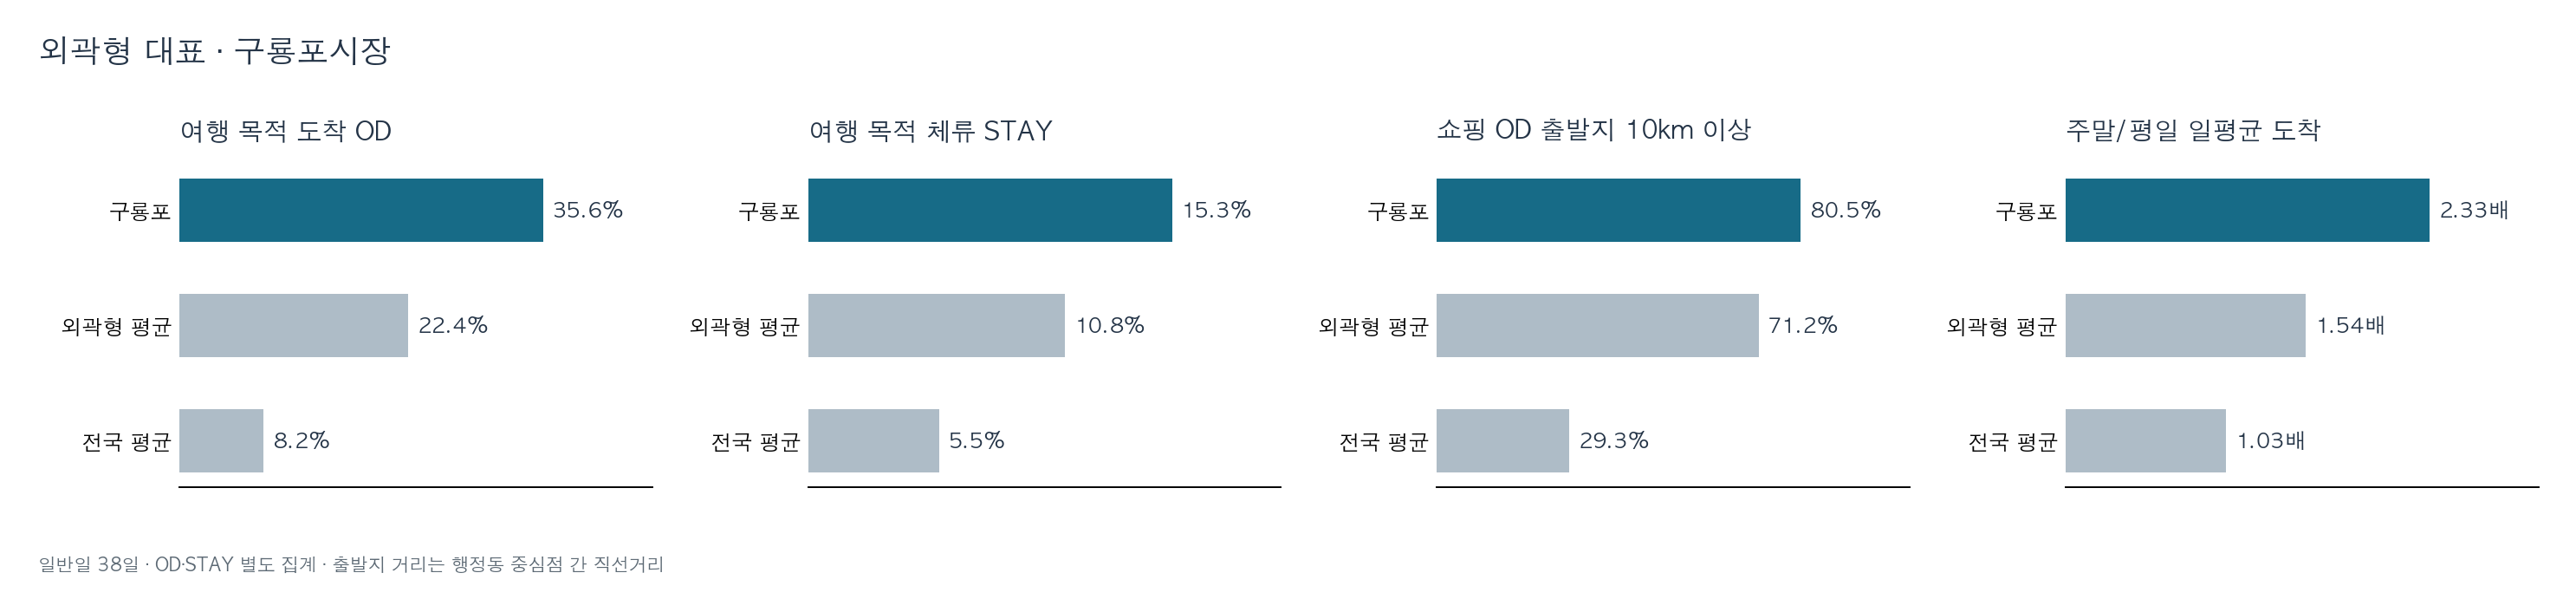

In [2]:
filename, title, panels, note = CASE_COMPARISONS[CASE]
comparison = pd.DataFrame([
    {"지표": metric, "비교 대상": name, "값": value, "단위": unit}
    for metric, names, values, unit in panels
    for name, value in zip(names, values)
])
display(comparison)
plot_case_comparison(CASE)
display(Image(filename=str(FIGS / filename)))

## 시간·요일별 분포

,measure,daytype,정점 시각,시간별 구성비 (%)
6,도착 OD 전체,주말,14,13.0
23,도착 OD 전체,평일,15,8.6
38,체류 STAY 전체,주말,14,7.1
52,체류 STAY 전체,평일,12,6.9


,measure,day_of_week,요일별 구성비 (%),observed_days
0,도착 OD 전체,0,10.2,4
1,도착 OD 전체,1,9.1,5
2,도착 OD 전체,2,9.8,6
3,도착 OD 전체,3,9.9,5
4,도착 OD 전체,4,12.6,6
5,도착 OD 전체,5,24.8,6
6,도착 OD 전체,6,23.6,6
7,체류 STAY 전체,0,13.0,4
8,체류 STAY 전체,1,12.7,5
9,체류 STAY 전체,2,12.7,6


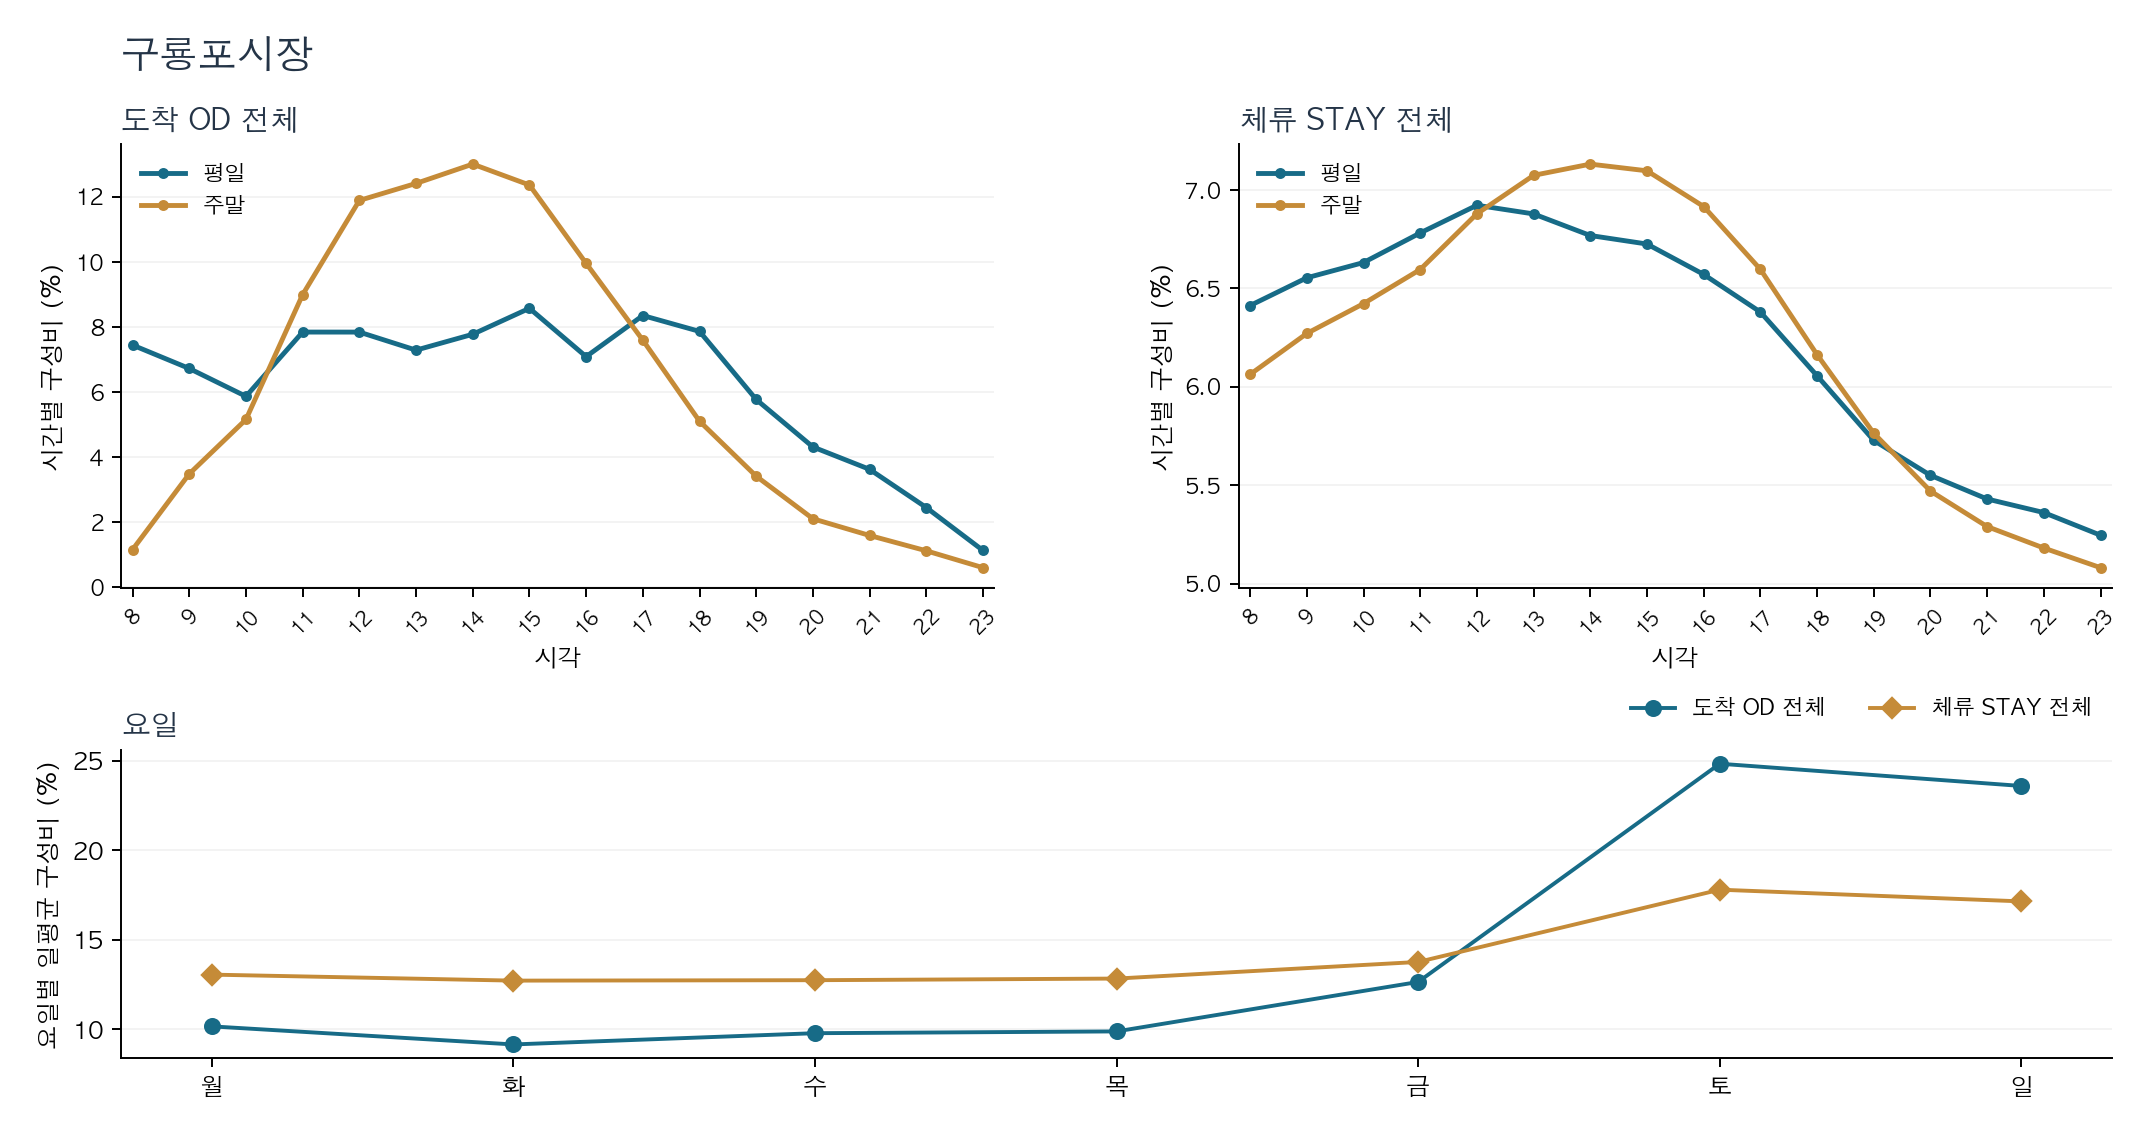

In [3]:
hourly = HOUR.loc[HOUR["case"].eq(CASE)].copy()
peaks = hourly.loc[hourly.groupby(["measure", "daytype"])["hour_share"].idxmax(),
                   ["measure", "daytype", "hour", "hour_share"]].copy()
peaks["hour_share"] = (peaks["hour_share"] * 100).round(1)
display(peaks.rename(columns={"hour":"정점 시각", "hour_share":"시간별 구성비 (%)"}))
weekday = WEEK.loc[WEEK["case"].eq(CASE)].copy()
weekday["요일별 구성비 (%)"] = weekday.groupby("measure")["daily_index"].transform(
    lambda values: values / values.sum() * 100
).round(1)
display(weekday[["measure", "day_of_week", "요일별 구성비 (%)", "observed_days"]])
plot_time_weekday(CASE)
display(Image(filename=str(FIGS / TIME_FIGURES[CASE])))

## 주변 조건

* 그림: 비공개 시설·공간 입력으로 작성한 저장 결과
* 재생성: 비공개 입력 경로 지정 시 가능

비공개 시설·시간 입력이 없어 저장된 편의 조건 그림을 표시합니다.


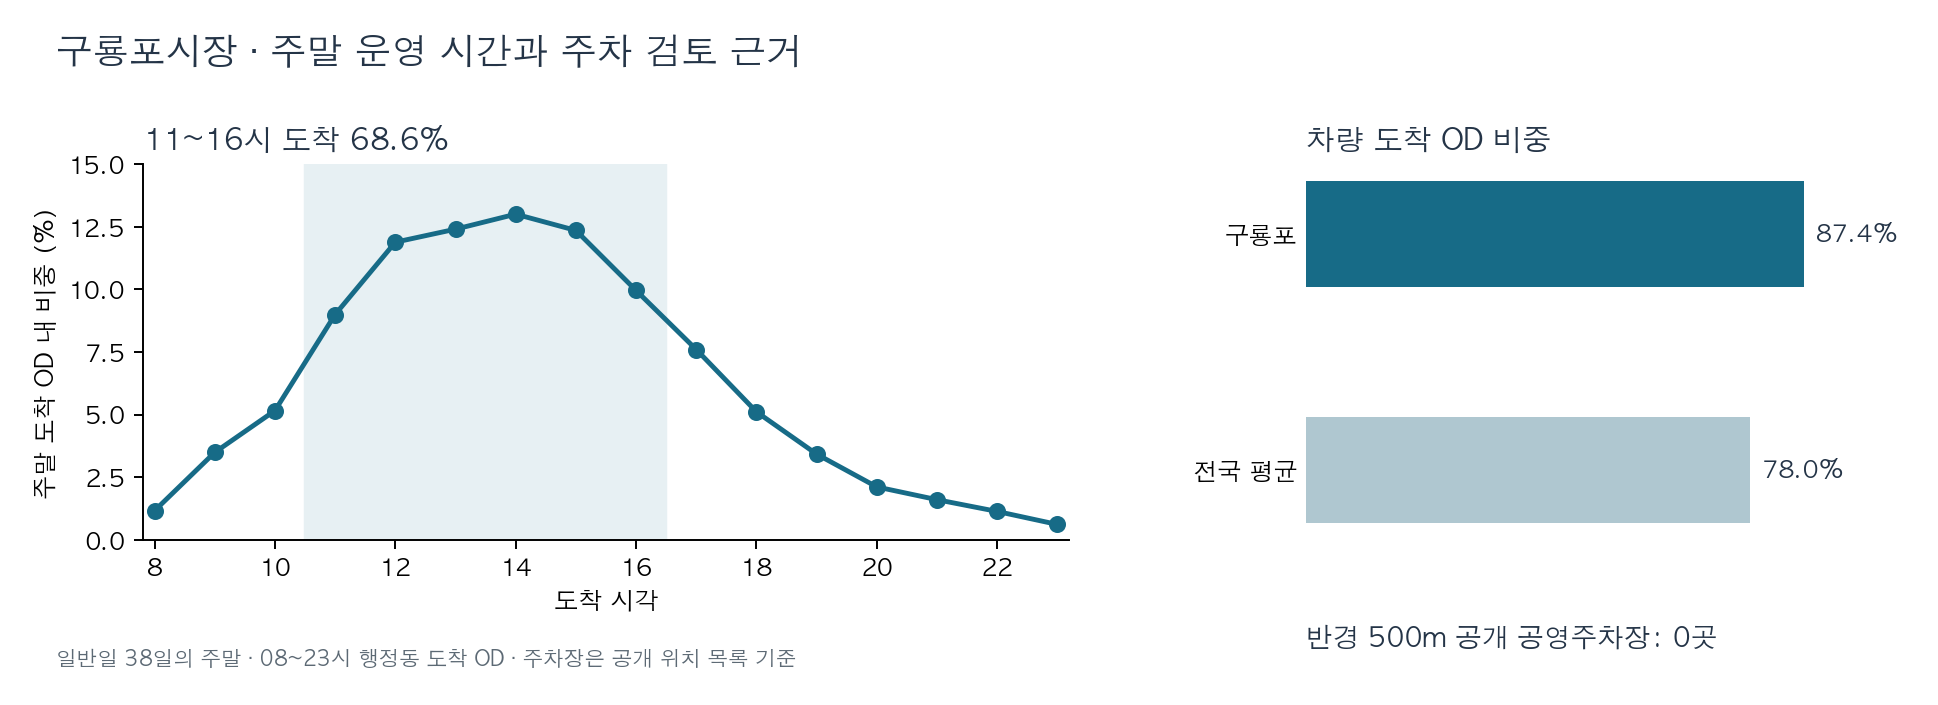

In [4]:
import os
from plotting import guryongpo
features_path = os.environ.get("BC_MARKET_FEATURES")
hourly_path = os.environ.get("BC_GURYONGPO_HOURLY")
figure_path = Path("../figs") / "fig_v4_1b_guryongpo_time_parking.png"
if all(p and Path(p).exists() for p in [features_path, hourly_path]):
    features = pd.read_csv(features_path)
    hourly_source = pd.read_csv(hourly_path)
    guryongpo(features, hourly_source)
    figure_path = FIGS / "fig_v4_1b_guryongpo_time_parking.png"
else:
    print("비공개 시설·시간 입력이 없어 저장된 편의 조건 그림을 표시합니다.")
display(Image(filename=str(figure_path)))

## 제안

* 방안: 주말 운영과 소포장·택배 발송, 임시 주차 가능성 검토
* 상태: 시행·효과 미확인